# Assignment 5: Histogram Equalization and Histogram Matching

1. Enhance the contrast of a grayscale image using **histogram equalization**, and display the original and equalized images.
2. Perform **histogram matching** of an input image with a reference image, using histogram equalization.

**Requirements:** `pip install numpy matplotlib opencv-python scikit-image`

## Setup

To use your own images, set the paths below, for example `INPUT_PATH = "input.jpg"`.
If a path is left as `None`, a sample image from scikit-image is used.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

INPUT_PATH = None        # image to enhance
REFERENCE_PATH = None    # image whose histogram is to be matched

L = 256   # number of gray levels


def load_gray(path, sample):
    """Read an image from path as 8-bit grayscale, or return the sample image."""
    if path is None:
        return sample
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"Could not read image: {path}")
    return img


input_img = load_gray(INPUT_PATH, data.moon())
reference_img = load_gray(REFERENCE_PATH, data.camera())
print("Input image shape:    ", input_img.shape)
print("Reference image shape:", reference_img.shape)

Input image shape:     (512, 512)
Reference image shape: (512, 512)


## Part 1: Histogram Equalization

The transformation maps each gray level $r_k$ to a new level $s_k$ using the cumulative distribution function (CDF):

$$s_k = T(r_k) = (L-1)\sum_{j=0}^{k} p_r(r_j), \qquad p_r(r_j) = \frac{n_j}{MN}$$

where $n_j$ is the number of pixels with gray level $r_j$ and $MN$ is the total number of pixels.

**Steps**
1. Compute the histogram of the image.
2. Normalize it to get the PDF.
3. Compute the CDF.
4. Multiply by $L-1$ and round to get the mapping.
5. Replace each pixel using the mapping.

In [2]:
def compute_histogram(img):
    """Count the number of pixels at each gray level."""
    hist = np.zeros(L, dtype=np.int64)
    for value in img.ravel():
        hist[value] += 1
    return hist


def equalization_map(img):
    """Return the lookup table T(r) = round((L-1) * CDF(r))."""
    hist = compute_histogram(img)
    pdf = hist / img.size
    cdf = np.cumsum(pdf)
    return np.round((L - 1) * cdf).astype(np.uint8)


def histogram_equalization(img):
    """Apply histogram equalization to a grayscale image."""
    return equalization_map(img)[img]


def show_results(images, titles):
    """Show each image above its histogram."""
    fig, axes = plt.subplots(2, len(images), figsize=(5 * len(images), 7))
    for i, (img, title) in enumerate(zip(images, titles)):
        axes[0, i].imshow(img, cmap="gray", vmin=0, vmax=255)
        axes[0, i].set_title(title)
        axes[0, i].axis("off")
        axes[1, i].bar(range(L), compute_histogram(img), width=1, color="#333333")
        axes[1, i].set_title(f"Histogram: {title}")
        axes[1, i].set_xlabel("Gray level")
        axes[1, i].set_ylabel("Pixel count")
        axes[1, i].set_xlim(0, 255)
    plt.tight_layout()
    plt.show()

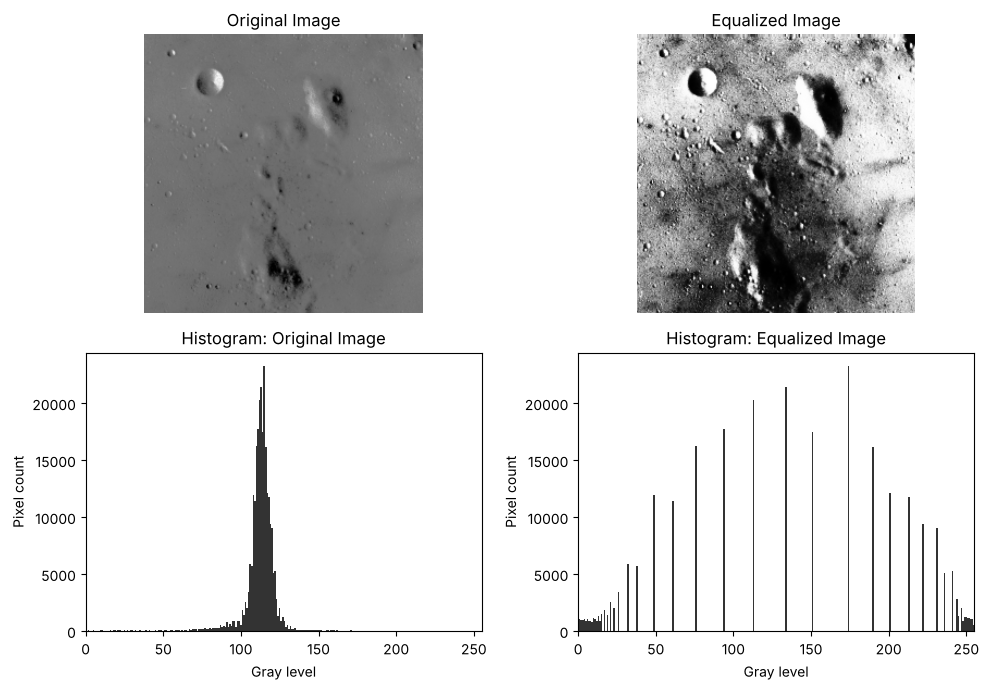

Original  - range: 0 to 255, std dev: 13.33
Equalized - range: 0 to 255, std dev: 73.90


In [3]:
equalized_img = histogram_equalization(input_img)

show_results([input_img, equalized_img], ["Original Image", "Equalized Image"])

print(f"Original  - range: {input_img.min()} to {input_img.max()}, std dev: {input_img.std():.2f}")
print(f"Equalized - range: {equalized_img.min()} to {equalized_img.max()}, std dev: {equalized_img.std():.2f}")

## Part 2: Histogram Matching

Histogram matching (specification) changes the input image so that its histogram resembles that of a reference image. It uses equalization as an intermediate step, because equalizing either image gives an approximately uniform histogram.

**Steps**
1. Equalize the input image: $s = T(r)$.
2. Equalize the reference image: $v = G(z)$.
3. For each $s$, find the smallest $z$ such that $G(z) \ge s$, which gives $z = G^{-1}(s)$.
4. Replace each input pixel using the combined mapping $r \rightarrow z = G^{-1}(T(r))$.

In [4]:
def histogram_matching(img, reference):
    """Match the histogram of img to that of reference using equalization maps."""
    T = equalization_map(img)         # input level -> equalized level
    G = equalization_map(reference)   # reference level -> equalized level

    mapping = np.zeros(L, dtype=np.uint8)
    for r in range(L):
        # Smallest z with G(z) >= T(r). G is non-decreasing, so a search works.
        z = np.searchsorted(G, T[r], side="left")
        mapping[r] = min(z, L - 1)

    return mapping[img]

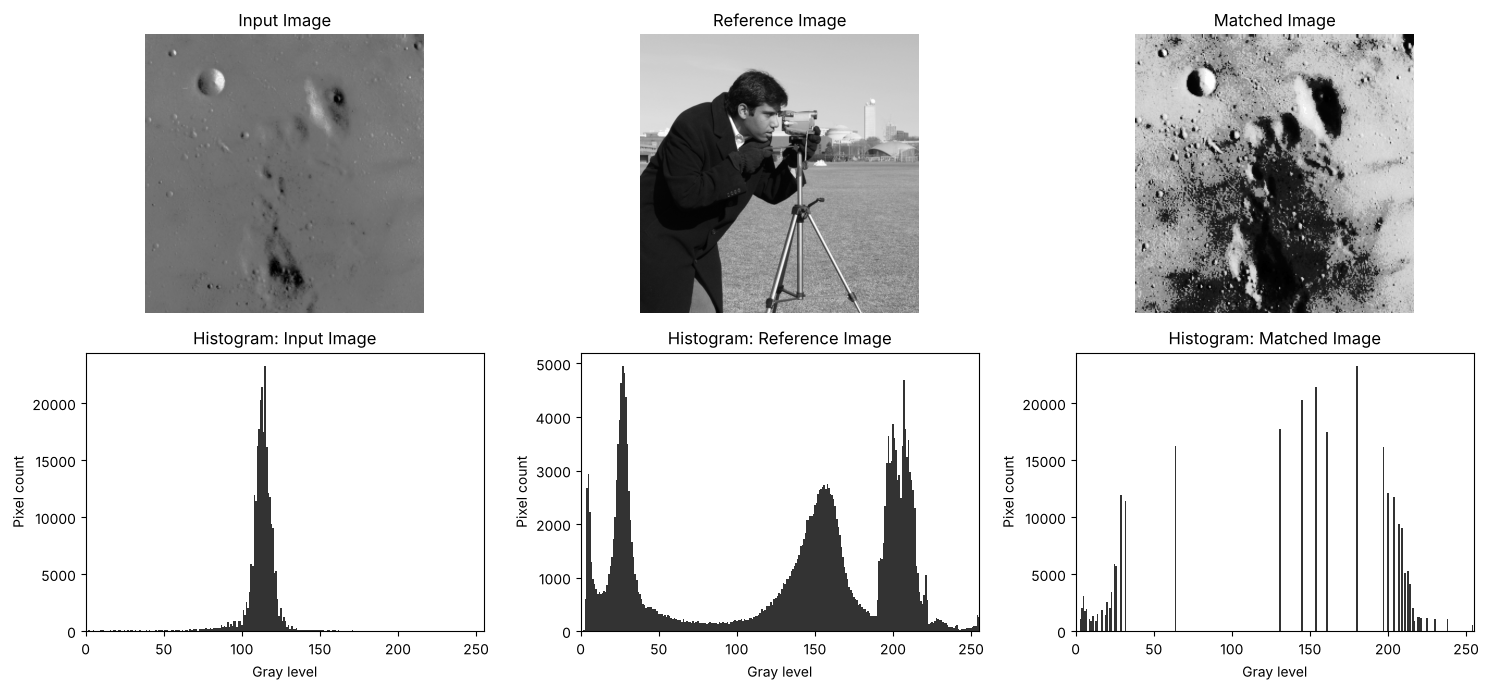

In [5]:
matched_img = histogram_matching(input_img, reference_img)

show_results(
    [input_img, reference_img, matched_img],
    ["Input Image", "Reference Image", "Matched Image"],
)

### CDF comparison

If the matching has worked, the CDF of the matched image should closely follow the CDF of the reference image.

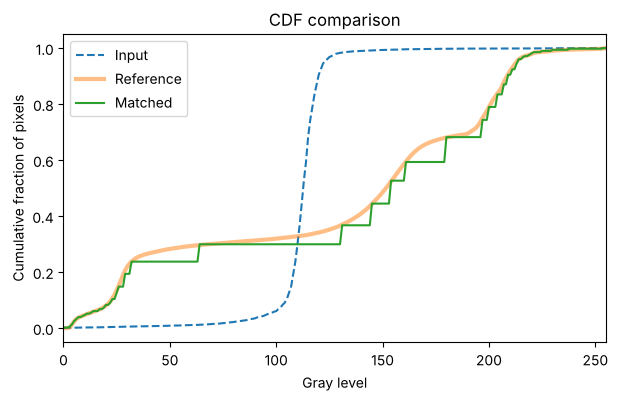

Mean CDF difference from reference, before matching: 0.2475
Mean CDF difference from reference, after matching:  0.0215


In [6]:
def compute_cdf(img):
    return np.cumsum(compute_histogram(img)) / img.size


plt.figure(figsize=(7, 4))
plt.plot(compute_cdf(input_img), label="Input", linestyle="--")
plt.plot(compute_cdf(reference_img), label="Reference", linewidth=3, alpha=0.5)
plt.plot(compute_cdf(matched_img), label="Matched")
plt.title("CDF comparison")
plt.xlabel("Gray level")
plt.ylabel("Cumulative fraction of pixels")
plt.xlim(0, 255)
plt.legend()
plt.show()

gap_before = np.abs(compute_cdf(input_img) - compute_cdf(reference_img)).mean()
gap_after = np.abs(compute_cdf(matched_img) - compute_cdf(reference_img)).mean()
print(f"Mean CDF difference from reference, before matching: {gap_before:.4f}")
print(f"Mean CDF difference from reference, after matching:  {gap_after:.4f}")

## Conclusion

- **Histogram equalization** spreads the gray levels over the full range using the image's CDF, which increases contrast.
- **Histogram matching** uses the equalization maps of both images to give the input image a gray-level distribution close to that of the reference image.
- Because the images are digital, the resulting histograms are close approximations rather than perfectly flat or identical.